# 🧬 Práctica B: Anotación de Genomas con conda en Google Colab

> ⚠️ **IMPORTANTE: antes de continuar**, lea la [guía de prácticas compartida](00_genome_annotation_common.md) — contiene el contexto biológico de cada caso, los conceptos clave, las plataformas y la descripción de los archivos de salida.

Esta práctica sigue el mismo flujo de trabajo que la **Práctica A** (Galaxy), pero ejecutando las herramientas desde la línea de comandos en un entorno Google Colab + conda. Esto le permite:

- Instalar y usar herramientas bioinformáticas de CLI sin necesitar un servidor institucional.
- Integrar los resultados directamente en Python con `pandas` y `matplotlib`.
- Comprender cómo se encadenan estas herramientas en un pipeline automatizado.

---

## ⚙️ Paso 0 — Configurar el entorno

Ejecute esta celda **primero**. Instala Miniconda y todas las herramientas necesarias.
⏱️ Puede tardar 8–12 minutos.

In [ ]:
# Instalamos Conda para Colab

!pip install condacolab --quiet

import condacolab
condacolab.install() # Esto reinicia el kernel automáticamente

Tras el reinicio del kernel, ejecuta esta celda para confirmar que el entorno quedó correctamente configurado y para dejar registradas las versiones de las herramientas base (útil para citar en la sección de métodos de informes/artículos).

In [ ]:
# Verificar instalación de condacolab y registrar versiones del entorno base
import os
import sys
import subprocess

os.environ['PATH'] = '/usr/local/bin:/opt/conda/bin:' + os.environ['PATH']

# Instalar biopython
!pip install biopython --quiet

def version_pip(paquete):
    res = subprocess.run(["pip", "show", paquete], capture_output=True, text=True)
    for linea in res.stdout.splitlines():
        if linea.startswith("Version:"):
            return linea.split(":", 1)[1].strip()
    return "⚠️ no encontrado"

conda_version = subprocess.run(["conda", "--version"], capture_output=True, text=True).stdout.strip()

# google-colab no se instala vía pip estándar en el entorno conda (es parte
# de la integración interna del runtime), por lo que 'pip show' no lo detecta
# de forma confiable. Verificamos disponibilidad importando el módulo.
try:
    import google.colab  # noqa: F401
    colab_estado = "disponible (ejecutando en Google Colab)"
except ImportError:
    colab_estado = "no detectado (¿no estás en Google Colab?)"

print("📦 Versiones del entorno base:")
print(f"  - Python: {sys.version.split()[0]}")
print(f"  - {conda_version}")
print(f"  - biopython: {version_pip('biopython')}")
print(f"  - Google Colab: {colab_estado}")

Una vez que Conda esté instalado, es posible que necesites reiniciar el entorno de ejecución de Colab (Runtime > Restart runtime) para que los cambios surtan efecto. Después de reiniciar, puedes ejecutar comandos `conda` en nuevas celdas de código.

### Instalar herramientas

Ya que hemos instalado **Conda** es necesario instalar las herramientas que vamos a usar para el ensamblaje.

In [ ]:
# Instalar herramientas bioinformáticas

# Nota: antiSMASH NO se instala aquí porque entra en conflicto de versión de
# Python con bakta. Se instala por separado en el Paso 9. La misma situación
# pasa con IntegronFinder. Se instala por separado en el paso 6.

# El log completo de conda es muy largo (incluye decenas de dependencias de
# soporte) y poco útil para reportes. Lo capturamos y, si todo sale bien,
# solo mostramos un resumen con las versiones de las herramientas pedidas
# (útil para citar versiones en informes/artículos). Si algo falla, se
# muestra el log completo para poder depurar.
import json

herramientas = [
    "bakta",
    "ncbi-amrfinderplus",
    "plasmidfinder",
    "isescan",
]

def mostrar_versiones_instaladas(paquetes):
    """Imprime una tabla compacta con nombre y versión de cada paquete instalado.
    Nota: 'conda list' solo acepta UN patrón regex como filtro, por eso se
    listan todos los paquetes del entorno y se filtra en Python."""
    res = subprocess.run(["conda", "list", "--json"], capture_output=True, text=True)
    try:
        instalados = {p["name"]: p["version"] for p in json.loads(res.stdout)}
    except (json.JSONDecodeError, KeyError):
        instalados = {}
    print("\n📦 Versiones instaladas:")
    for pkg in paquetes:
        print(f"  - {pkg}: {instalados.get(pkg, '⚠️ no encontrado')}")

print("Instalando herramientas bioinformáticas (esto puede tardar varios minutos)...")
cmd = ["conda", "install", "-y", "-c", "bioconda", "-c", "conda-forge"] + herramientas
resultado = subprocess.run(cmd, capture_output=True, text=True)

if resultado.returncode == 0:
    print("✅ Herramientas bioinformáticas instaladas")
    mostrar_versiones_instaladas(herramientas)
else:
    print("❌ Falló la instalación. Log completo de conda:\n")
    print(resultado.stdout)
    print(resultado.stderr)
    raise RuntimeError("La instalación de herramientas bioinformáticas falló. Revisa el log arriba.")

ahora vamos a instalar otras herramientas propias de **Python** que nos ayudaran a procesar y ver los resutlados mas facil para los humanos

In [ ]:
# Instalar y verificar el resultado
result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "matplotlib", "pandas", "--quiet"],
    capture_output=True, text=True
)
if result.returncode != 0:
    raise RuntimeError(f"❌ Falló pip install:\n{result.stderr}")

# Imports centralizados
import json, glob, pathlib, gzip, shutil
from IPython.display import Image, display, SVG

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

os.environ['PATH'] = '/opt/conda/bin:' + os.environ['PATH']

# Confirmar versiones realmente cargadas
print(f"✅ matplotlib {matplotlib.__version__}")
print(f"✅ pandas {pd.__version__}")
print("✅ Dependencias Python listas")

Ahora vamos a definir algunas funciones que vamos a necesitar para mostrar el avance en desscargas y otros, e importar algunas librerias que usaremos leugo

In [ ]:
def run_live(cmd, outputs=()):
    """Como run(), pero muestra la salida del programa en la celda en tiempo real."""
    if not shutil.which(cmd[0]):
        raise RuntimeError(f"❌ No se encontró {cmd[0]} en el PATH")
    env = {**os.environ, "PYTHONUNBUFFERED": "1"}   # evita que Python agrupe la salida
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            text=True, bufsize=1, env=env)
    for c in iter(lambda: proc.stdout.read(1), ""):   # carácter a carácter (respeta '\r')
        sys.stdout.write(c)
        sys.stdout.flush()
    proc.wait()
    if proc.returncode != 0:
        raise RuntimeError(f"❌ Falló (código {proc.returncode}): {' '.join(cmd)}")
    for p in outputs:
        if not os.path.exists(p) or os.path.getsize(p) == 0:
            raise RuntimeError(f"❌ Falta o está vacío: {p}")

## 📥 Paso 1 — Descargar los datos del caso asignado

Solo trabajaremos con un solo caso. Use el **mismo número** que trabajó en los Módulos 4 (filogenética) y 5 (ensamblaje) — asígnelo a la variable `CASO` ("01" a "20").

A diferencia del Módulo 5, aquí **no se descargan lecturas FASTQ ni se ensambla nada**: se descarga directamente el **genoma de referencia de NCBI** (el mismo usado para evaluar con QUAST en el Módulo 5) y se anota tal cual. Esto garantiza que todos los estudiantes con el mismo caso trabajen sobre un genoma idéntico y completo.

Consulte la [guía compartida](00_genome_annotation_common.md#-casos-de-estudio) para la tabla completa de casos, grupos de AMRFinderPlus y recomendación de antiSMASH.

In [ ]:
# ⚠️ **IMPORTANTE**: Define el caso a trabajar aquí y solo aquí.
# Use el MISMO número de caso que trabajó en los Módulos 4 y 5 ("01" a "20").
CASO = "01"  # Por ejemplo, para el caso 1 (Klebsiella pneumoniae)

In [ ]:
# Diccionario con los 20 casos: especie, genoma de referencia NCBI (el mismo usado para QUAST en el Módulo 5)
# y metadatos para las herramientas de abajo (grupo AMRFinderPlus, si antiSMASH es especialmente recomendado).
# Caso 02: el Módulo 5 usó DOS referencias (una por tecnología, cepas distintas). Para anotación se usa
# una sola: el genoma COMPLETO (GCF_030285565.1, cepa C51) en lugar del borrador de 74 contigs.
CASOS_CONFIG = {
    "01": {"especie": "Klebsiella pneumoniae",       "genoma_mb": 5.5, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/061/393/185/GCF_061393185.1_ASM6139318v1/GCF_061393185.1_ASM6139318v1_genomic.fna.gz",       "amr_organismo": "Klebsiella_pneumoniae",     "antismash_recomendado": False},
    "02": {"especie": "Escherichia coli",             "genoma_mb": 5.0, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/030/285/565/GCF_030285565.1_ASM3028556v1/GCF_030285565.1_ASM3028556v1_genomic.fna.gz",       "amr_organismo": "Escherichia",               "antismash_recomendado": False},
    "03": {"especie": "Pseudomonas abieticivorans",   "genoma_mb": 6.7, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/023/509/015/GCF_023509015.1_ASM2350901v1/GCF_023509015.1_ASM2350901v1_genomic.fna.gz",       "amr_organismo": "Pseudomonas_aeruginosa",    "antismash_recomendado": True},
    "04": {"especie": "Streptomyces venezuelae",      "genoma_mb": 8.2, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/050/632/295/GCA_050632295.1_ASM5063229v1/GCA_050632295.1_ASM5063229v1_genomic.fna.gz",       "amr_organismo": None,                         "antismash_recomendado": True},
    "05": {"especie": "Streptomyces coelicolor",      "genoma_mb": 8.7, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/047/824/265/GCF_047824265.1_ASM4782426v1/GCF_047824265.1_ASM4782426v1_genomic.fna.gz",       "amr_organismo": None,                         "antismash_recomendado": True},
    "06": {"especie": "Bacillus subtilis",            "genoma_mb": 4.2, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/982/518/465/GCF_982518465.1_NRS2125/GCF_982518465.1_NRS2125_genomic.fna.gz",                 "amr_organismo": None,                         "antismash_recomendado": True},
    "07": {"especie": "Staphylococcus aureus (MRSA)",  "genoma_mb": 2.8, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/982/303/505/GCF_982303505.1_24S859_ONT_hybrid/GCF_982303505.1_24S859_ONT_hybrid_genomic.fna.gz", "amr_organismo": "Staphylococcus_aureus",     "antismash_recomendado": False},
    "08": {"especie": "Vibrio cholerae",               "genoma_mb": 4.0, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/055/797/365/GCF_055797365.1_ASM5579736v1/GCF_055797365.1_ASM5579736v1_genomic.fna.gz",       "amr_organismo": "Vibrio_cholerae",           "antismash_recomendado": False},
    "09": {"especie": "Mycobacterium tuberculosis",    "genoma_mb": 4.4, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/061/392/705/GCF_061392705.1_ASM6139270v1/GCF_061392705.1_ASM6139270v1_genomic.fna.gz",       "amr_organismo": "Mycobacterium_tuberculosis","antismash_recomendado": False},
    "10": {"especie": "Agrobacterium tumefaciens",     "genoma_mb": 5.6, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/047/731/285/GCA_047731285.1_ASM4773128v1/GCA_047731285.1_ASM4773128v1_genomic.fna.gz",       "amr_organismo": None,                         "antismash_recomendado": False},
    "11": {"especie": "Deinococcus radiodurans",       "genoma_mb": 3.3, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/045/277/105/GCF_045277105.1_KDR13939K_1.0/GCF_045277105.1_KDR13939K_1.0_genomic.fna.gz",       "amr_organismo": None,                         "antismash_recomendado": False},
    "12": {"especie": "Thermus thermophilus",          "genoma_mb": 2.1, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/059/705/435/GCF_059705435.1_ASM5970543v1/GCF_059705435.1_ASM5970543v1_genomic.fna.gz",       "amr_organismo": None,                         "antismash_recomendado": False},
    "13": {"especie": "Lactobacillus acidophilus",     "genoma_mb": 2.0, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/988/235/355/GCF_988235355.1_IF3HA23006/GCF_988235355.1_IF3HA23006_genomic.fna.gz",         "amr_organismo": None,                         "antismash_recomendado": False},
    "14": {"especie": "Helicobacter pylori",           "genoma_mb": 1.6, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/059/997/335/GCA_059997335.1_ASM5999733v1/GCA_059997335.1_ASM5999733v1_genomic.fna.gz",       "amr_organismo": None,                         "antismash_recomendado": False},
    "15": {"especie": "Salmonella enterica",           "genoma_mb": 4.8, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/061/253/545/GCF_061253545.1_ASM6125354v1/GCF_061253545.1_ASM6125354v1_genomic.fna.gz",       "amr_organismo": "Salmonella",                "antismash_recomendado": False},
    "16": {"especie": "Bacillus licheniformis",        "genoma_mb": 4.3, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/055/397/075/GCA_055397075.1_ASM5539707v1/GCA_055397075.1_ASM5539707v1_genomic.fna.gz",       "amr_organismo": None,                         "antismash_recomendado": False},
    "17": {"especie": "Paenibacillus polymyxa",        "genoma_mb": 5.8, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/056/645/015/GCF_056645015.1_ASM5664501v1/GCF_056645015.1_ASM5664501v1_genomic.fna.gz",       "amr_organismo": None,                         "antismash_recomendado": True},
    "18": {"especie": "Synechocystis sp.",             "genoma_mb": 3.6, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/987/480/225/GCA_987480225.1_glgC6/GCA_987480225.1_glgC6_genomic.fna.gz",                     "amr_organismo": None,                         "antismash_recomendado": False},
    "19": {"especie": "Enterococcus faecalis",         "genoma_mb": 3.0, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCA/061/255/735/GCA_061255735.1_ASM6125573v1/GCA_061255735.1_ASM6125573v1_genomic.fna.gz",       "amr_organismo": "Enterococcus_faecalis",     "antismash_recomendado": False},
    "20": {"especie": "Shewanella oneidensis",         "genoma_mb": 4.9, "ref_url": "https://ftp.ncbi.nlm.nih.gov/genomes/all/GCF/000/146/165/GCF_000146165.2_ASM14616v2/GCF_000146165.2_ASM14616v2_genomic.fna.gz",         "amr_organismo": None,                         "antismash_recomendado": False},
}

if "CASO" not in globals():
    raise NameError('Define CASO antes de esta celda, por ejemplo: CASO = "02"')

if CASO not in CASOS_CONFIG:
    raise ValueError(f"⚠️ CASO '{CASO}' no reconocido. Use un número de \"01\" a \"20\".")

cfg = CASOS_CONFIG[CASO]
print(f"── Caso {CASO}: {cfg['especie']} (~{cfg['genoma_mb']} Mb) ──")

workdir = f"genome_annotation/caso_{CASO}"   # typo corregido
os.makedirs(f"{workdir}/data", exist_ok=True)

ref_gz = f"{workdir}/data/ref.fna.gz"
contigs_path = f"{workdir}/data/contigs.fasta"

# Descarga: check=True detiene la celda si wget falla
print("Descargando genoma de referencia (el mismo usado para QUAST en el Módulo 5)...")
subprocess.run(["wget", "-q", cfg["ref_url"], "-O", ref_gz], check=True)

size = os.path.getsize(ref_gz)
print(f"  Descargado: {size:,} bytes")
if size < 1000:
    raise RuntimeError(f"❌ Descarga fallida o archivo vacío: {ref_gz}")

# Descomprimir directamente a contigs.fasta (sin el rename intermedio)
with gzip.open(ref_gz, "rb") as f_in, open(contigs_path, "wb") as f_out:
    shutil.copyfileobj(f_in, f_out)

# Contar secuencias
with open(contigs_path) as f:
    num_contigs = sum(1 for line in f if line.startswith(">"))

if num_contigs == 0:
    raise RuntimeError("❌ El FASTA no contiene secuencias")

print(f"✅ Caso {CASO} listo — {num_contigs} secuencia(s) en {contigs_path}")

## 👀 Paso 1.1 — Inspeccionar los archivos descargados

Vamos a verificar que los archivos FASTQ y el genoma de referencia FASTA se hayan descargado correctamente y tengan el formato esperado. Revisaremos el encabezado de cada uno.

In [ ]:
print(f"=== Encabezado del archivo FASTA de contigs para {CASO} ===")
!head -n 10 "{contigs_path}"

print(f"\n=== Estadísticas básicas ===")
!grep -c '>' "{contigs_path}" | awk '{{print "Contigs totales: " $1}}'
!awk '/^>/{{next}}{{total+=length($0)}} END{{print "Bases totales: " total}}' "{contigs_path}"

## 🏷️ Paso 2 — Anotación principal con Bakta

Bakta realiza la anotación estructural (CDS, ARNt, ARNr, ncRNA, CRISPR) y funcional en un solo paso.

> **Nota:** Bakta requiere su base de datos. La descargamos en formato light (~1 GB) — suficiente para esta práctica. El tiempo que toma este paso dependerá de la velocidad de conexión de su internet

In [ ]:
db_dir = "/content/opt/bakta_db"
db_light = f"{db_dir}/db-light"
marcador = f"{db_dir}/.descarga_ok"
TAM_MIN_GB = 0.8
os.makedirs(db_dir, exist_ok=True)

def tam_gb(path):
    total = 0
    for raiz, _, archivos in os.walk(path):
        for a in archivos:
            try:
                total += os.path.getsize(os.path.join(raiz, a))
            except OSError:
                pass
    return total / 1e9

def db_completa():
    return (os.path.exists(f"{db_light}/version.json")
            and tam_gb(db_light) >= TAM_MIN_GB)

if os.path.exists(marcador) and db_completa():
    print(f"ℹ️ La base ya existe en {db_light}, se omite la descarga")
else:
    if os.path.exists(marcador):
        os.remove(marcador)
    !bakta_db download --output /content/opt/bakta_db --type light

    if not db_completa():
        raise RuntimeError(
            f"❌ La base no quedó completa en {db_light} "
            f"({tam_gb(db_light):.2f} GB; se esperaban al menos {TAM_MIN_GB} GB). "
            "Borra la carpeta y vuelve a ejecutar."
        )
    open(marcador, "w").close()

print(f"✅ Base de datos Bakta lista en {db_light} ({tam_gb(db_light):.2f} GB)")

Este paso demora aproximadamente 20 minutos

In [ ]:
# Guardar y limpiar temporalmente la variable de Jupyter para evitar el conflicto en el subproceso
if 'MPLBACKEND' in os.environ:
    del os.environ['MPLBACKEND']

bakta_out = f"{workdir}/results/bakta_results"
os.makedirs(bakta_out, exist_ok=True)

# Realizar la anotación con bakta
run_live(["bakta",
          "--db", "/content/opt/bakta_db/db-light",
          "--output", bakta_out,
          "--force",
          "--prefix", "genome",
          "--keep-contig-headers",
          "--skip-sorf",
          "--threads", "2",
          contigs_path],
         outputs=[f"{bakta_out}/genome.gff3", f"{bakta_out}/genome.tsv"],)

print(f"✅ Bakta completo. Resultados en {bakta_out}/")

## 📊 Paso 3 — Explorar el resumen de Bakta con Python

In [ ]:
# Extraer métricas clave del resumen
txt_path = pathlib.Path(f"{bakta_out}/genome.txt")
print(txt_path.read_text())

### Visualización del `circular plot` generado por Bakta

In [ ]:
bakta_dir = pathlib.Path(bakta_out)
print(f"Archivos en {bakta_out}:")
for p in sorted(bakta_dir.iterdir()):
    print(f"  {p.name}  ({p.stat().st_size:,} bytes)")

circular_plot_path = bakta_dir / "genome.svg"

if not circular_plot_path.exists():
    raise FileNotFoundError(
        f"❌ No se encontró {circular_plot_path}. Verifique que Bakta haya completado correctamente."
    )

print(f"\nMostrando el circular plot: {circular_plot_path}")
display(SVG(filename=str(circular_plot_path)))

**Preguntas:**

1. ¿Cuántas secuencias/contigs había en el genoma de referencia usado?
2. ¿Cuál es la longitud total del genoma?
3. ¿Cuántos CDS fueron predichos?
4. ¿Cuántas *small proteins* se encontraron?
5. ¿Cuántos ARNt y ARNr se anotaron?
6. ¿Hay secuencias CRISPR?
7. Compare el número de CDS reportado por Bakta con la anotación original de NCBI/RefSeq para su accesión (columna "Referencia" en la [tabla de casos](00_genome_annotation_common.md#-casos-de-estudio)). ¿Coinciden aproximadamente?

## 🦠 Paso 4 — Genes de resistencia con AMRFinderPlus

In [ ]:
# El grupo taxonómico se toma automáticamente de CASOS_CONFIG
# (None si el caso no tiene grupo disponible en AMRFinderPlus)
ORGANISMO = cfg["amr_organismo"]
print(f"Grupo taxonómico AMRFinderPlus: {ORGANISMO if ORGANISMO else '(ninguno — búsqueda genérica)'}")

# Actualizar base de datos AMRFinder
run_live(["amrfinder", "-u"])
print("✅ Base de datos AMRFinder actualizada")

amr_out = f"{workdir}/results/amrfinder_results"
os.makedirs(amr_out, exist_ok=True)
amr_tsv = f"{amr_out}/amrfinder.tsv"

# Construye el comando a ejecutar con base en el grupo taxonomico del microorganismo
cmd = ["amrfinder",
       "--nucleotide", contigs_path,
       "-o", amr_tsv,
       "--plus",
       "--threads", "2"]
if ORGANISMO:
    cmd += ["--organism", ORGANISMO]

run_live(cmd, outputs=[amr_tsv])
print("✅ AMRFinderPlus completo")


In [ ]:
# Mostrar resultados con pandas en vez de !head
df_amr = pd.read_csv(amr_tsv, sep="\t")
print(f"Elementos detectados: {len(df_amr)}")

cols_deseadas = ["Element symbol", "Contig id", "Class", "Subclass", "% Identity to reference sequence"]
cols_disponibles = [c for c in cols_deseadas if c in df_amr.columns]

faltantes = set(cols_deseadas) - set(cols_disponibles)
if faltantes:
    print(f"⚠️ Columnas no encontradas: {faltantes}")
    print(f"   Columnas reales: {list(df_amr.columns)}")

if df_amr.empty:
    print("ℹ️ AMRFinderPlus no detectó ningún elemento en este caso")
else:
    print(df_amr[cols_disponibles].to_string(index=False))

**Preguntas:**

8. ¿Qué genes de resistencia a antibióticos se encontraron?
9. ¿A qué familias de antibióticos pertenecen (columna `Class`)?
10. ¿En qué contigs se encuentran?
11. ¿Se encontraron factores de virulencia?

## 🔵 Paso 5 — Identificación de plásmidos con PlasmidFinder

In [ ]:
pf_out = os.path.abspath(f"{workdir}/results/plasmidfinder_results")
if os.path.exists(pf_out):
    shutil.rmtree(pf_out)
os.makedirs(pf_out)

pf_exe = shutil.which("plasmidfinder.py") or shutil.which("plasmidfinder")
if not pf_exe:
    raise RuntimeError("❌ No se encontró plasmidfinder en el PATH")

patrones = [
    "/usr/local/share/plasmidfinder*/database",
    "/opt/conda/share/plasmidfinder*/database",
    "/content/**/plasmidfinder_db",
    "/content/**/plasmidfinder*/database",
    os.path.expanduser("~/plasmidfinder_db"),
]
cands = [p for pat in patrones for p in glob.glob(pat, recursive=True)
         if glob.glob(f"{p}/*.fsa")]          # solo carpetas que contengan secuencias
if not cands:
    raise RuntimeError("❌ No se encontró una base de datos de PlasmidFinder con archivos .fsa")
pf_db = cands[0]
print(f"Ejecutable: {pf_exe}\nBase de datos: {pf_db}\nSalida: {pf_out}\n")

run_live([pf_exe,
          "-i", os.path.abspath(contigs_path),
          "-o", pf_out,
          "-p", pf_db,
          "-x"])

# Revisar estas lineas luego, se debe solucionar que no lee -o
# Mover todo lo que PlasmidFinder dejó suelto en /content
sueltos = ["results_tab.tsv", "results.txt", "results_contigs.json",
           "Hit_in_genome_seq.fsa", "Plasmid_seqs.fsa"]
for nombre in sueltos:
    origen = f"/content/{nombre}"
    if os.path.exists(origen):
        shutil.move(origen, f"{pf_out}/{nombre}")
        print(f"↪ Movido: {nombre}")
# ----------------------------hasta acá

tsv = list(pathlib.Path(pf_out).rglob("results_tab.tsv"))
if not tsv:
    print("Archivos generados:")
    for p in sorted(pathlib.Path(pf_out).rglob("*")):
        print("  ", p.relative_to(pf_out))
    raise FileNotFoundError("❌ PlasmidFinder no generó results_tab.tsv")

pf_tsv = str(tsv[0])
print(f"\n✅ PlasmidFinder completo. Resultados: {pf_tsv}")

In [ ]:
pf_tsv = f"{pf_out}/results_tab.tsv"

if not os.path.exists(pf_tsv):
    raise FileNotFoundError(f"❌ No existe {pf_tsv}. ¿Corrió bien la celda de PlasmidFinder?")

pf_df = pd.read_csv(pf_tsv, sep="\t")
print(f"Replicones detectados: {len(pf_df)}\n")

cols_deseadas = ["Plasmid", "Identity", "Query / Template length", "Contig", "Position in contig"]
cols_pf = [c for c in cols_deseadas if c in pf_df.columns]

faltantes = set(cols_deseadas) - set(cols_pf)
if faltantes:
    print(f"⚠️ Columnas no encontradas: {faltantes}")
    print(f"   Columnas reales: {list(pf_df.columns)}")

if pf_df.empty:
    print("ℹ️ PlasmidFinder no detectó ningún replicón en este caso")
else:
    print(pf_df[cols_pf].to_string(index=False))

**Preguntas:**

12. ¿Cuántos plásmidos se identificaron?
13. ¿A qué replicones / familias pertenecen?
14. ¿En qué contigs se encuentran?
15. Cruzando con AMRFinderPlus: ¿algún gen de resistencia está en el mismo contig que un plásmido?

## 🔗 Paso 6 — Detección de integrones con IntegronFinder

> ⚠️ IntegronFinder no se instala con el bloque `conda install` anterior porque tiene dependencias que pueden entrar en conflicto. Se instala aquí de forma independiente.

In [ ]:
INTEGRON_ENV = "integron_env"

def integron_env_existe():
    res = subprocess.run(["conda", "env", "list", "--json"], capture_output=True, text=True)
    try:
        envs = json.loads(res.stdout).get("envs", [])
    except json.JSONDecodeError:
        envs = []
    return any(e.rstrip("/").endswith(INTEGRON_ENV) for e in envs)

if integron_env_existe():
    print(f"ℹ️ El entorno '{INTEGRON_ENV}' ya existe, se omite la instalación.")
    resultado = None
else:
    print(f"➡️ Creando entorno '{INTEGRON_ENV}' con integron_finder...")
    # Dejamos que conda resuelva la versión de Python compatible (Python 3.10+)
    cmd = ["conda", "create", "-y", "-n", INTEGRON_ENV, "-c", "conda-forge", "-c", "bioconda", "integron_finder"]
    resultado = subprocess.run(cmd, capture_output=True, text=True)

if resultado is None or resultado.returncode == 0:
    res = subprocess.run(["conda", "list", "-n", INTEGRON_ENV, "--json"], capture_output=True, text=True)
    try:
        version = next(p["version"] for p in json.loads(res.stdout) if p["name"] == "integron_finder")
    except (json.JSONDecodeError, StopIteration):
        version = "desconocida"
    print(f"✅ IntegronFinder instalado en el entorno '{INTEGRON_ENV}' (versión {version})")
else:
    print("❌ Falló la instalación. Log completo de conda:\n")
    print(resultado.stdout)
    print(resultado.stderr)
    raise RuntimeError("No se pudo instalar IntegronFinder. Revisa el log arriba.")

Ahora que lo hemos instalado si ejecutamos la busqueda de integrones

In [ ]:
integron_out = f"{workdir}/results/integron_results"
os.makedirs(integron_out, exist_ok=True)

# Guardar y limpiar temporalmente la variable de Jupyter para evitar el conflicto en el subproceso
if 'MPLBACKEND' in os.environ:
    del os.environ['MPLBACKEND']

run_live([
    "conda", "run", "-n", "integron_env",
    "integron_finder",
    "--local-max",
    "--func-annot",
    "--cpu", "2",
    "--outdir", integron_out,
    f"{workdir}/data/contigs.fasta"])

# IntegronFinder crea una subcarpeta Results_Integron_Finder_<nombre_del_fasta>
integron_files = glob.glob(f"{integron_out}/Results_Integron_Finder_*/*.integrons")
if not integron_files:
    raise RuntimeError(f"❌ No se generó el archivo .integrons en {integron_out}")

print("✅ IntegronFinder completo")
print(f"Archivo de resultados: {integron_files[0]}")

In [ ]:
integron_dir = pathlib.Path(integron_out)

# 1) Resumen por secuencia
summary_files = list(integron_dir.rglob("*.summary"))
if not summary_files:
    raise FileNotFoundError(f"❌ Falta el .summary en {integron_out}")

print(f"Archivo: {summary_files[0]}\n")
print(summary_files[0].read_text())

# 2) Detalle, solo si hay integrones detectados
integrons_files = list(integron_dir.rglob("*.integrons"))
if integrons_files:
    df_int = pd.read_csv(integrons_files[0], sep="\t", comment="#")
    if df_int.empty:
        print("ℹ️ No se detectaron integrones en este caso")
    else:
        print(f"\nElementos detectados: {len(df_int)}\n")
        print(df_int.to_string(index=False))

**Preguntas:**

16. ¿Cuántos integrones completos se encontraron?
17. ¿Cuántos elementos In0 y CALIN?
18. ¿En qué contigs se localizan?

## 🔀 Paso 7 — Detección de elementos IS con ISEScan

Este paso tarda aproximadamente 1 hora. Varia de acuerdo al caso al que se este trabajando

In [ ]:
isescan_out = f"{workdir}/results/isescan_results"
os.makedirs(isescan_out, exist_ok=True)

if not shutil.which("isescan.py"):
    raise RuntimeError("❌ No se encontró isescan.py en el PATH")

run_live(["isescan.py",
          "--seqfile", contigs_path,
          "--output", isescan_out,
          "--nthread", "2"])

# ISEScan guarda los resultados en subcarpetas, así que se busca de forma recursiva
out_dir = pathlib.Path(isescan_out)
tsv_files = list(out_dir.rglob("*.tsv"))
sum_files = list(out_dir.rglob("*.sum"))

if not tsv_files:
    print(f"Archivos en {isescan_out}:")
    for p in sorted(out_dir.rglob("*")):
        print("  ", p.relative_to(out_dir))
    raise RuntimeError("❌ ISEScan no generó el archivo .tsv de resultados")

print("✅ ISEScan completo")
print(f"Resultados: {tsv_files[0]}")
if sum_files:
    print(f"Resumen:    {sum_files[0]}")

In [ ]:
out_dir = pathlib.Path(isescan_out)
is_files = list(out_dir.rglob("*.tsv"))

if not is_files:
    print(f"Archivos en {isescan_out}:")
    for p in sorted(out_dir.rglob("*")):
        print("  ", p.relative_to(out_dir))
    raise FileNotFoundError("❌ No se encontró el .tsv de ISEScan. Verifique que la celda anterior terminó bien.")

print(f"Archivo: {is_files[0]}")
is_df = pd.read_csv(is_files[0], sep="\t")
print(f"Elementos IS detectados: {len(is_df)}\n")

# Verificar columnas (los nombres pueden variar entre versiones de ISEScan)
cols_deseadas = ["family", "cluster", "seqID", "isBegin", "isEnd"]
cols_is = [c for c in cols_deseadas if c in is_df.columns]

faltantes = set(cols_deseadas) - set(cols_is)
if faltantes:
    print(f"⚠️ Columnas no encontradas: {faltantes}")
    print(f"   Columnas reales: {list(is_df.columns)}")

if is_df.empty:
    print("ℹ️ ISEScan no detectó elementos IS en este caso")
else:
    print(is_df[cols_is].head(20).to_string(index=False))
    if "family" in is_df.columns:
        print("\nElementos por familia:")
        print(is_df["family"].value_counts().to_string())

**Preguntas:**

19. ¿Cuántos elementos IS se detectaron?
20. ¿En qué contigs se encuentran?
21. ¿Cuáles son las distintas familias de IS identificadas?

## 📊 Paso 8 — Resumen integrado con Python

Construye una tabla resumen que cruce los resultados de Bakta, AMRFinderPlus y PlasmidFinder por contig.

In [ ]:
# Verificar que existen los archivos de entrada
for ruta in (amr_tsv, pf_tsv):
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"❌ No existe {ruta}. Corre antes la celda correspondiente.")

amr_df = pd.read_csv(amr_tsv, sep="\t")
pf_df  = pd.read_csv(pf_tsv,  sep="\t")

# Columnas de contig: sin respaldo por posición, falla con mensaje claro
def col_contig(df, candidatas, nombre):
    for c in candidatas:
        if c in df.columns:
            return c
    raise KeyError(f"❌ No hay columna de contig en {nombre}. Columnas reales: {list(df.columns)}")

amr_col = col_contig(amr_df, ["Contig id", "Contig"], "AMRFinderPlus")
pf_col  = col_contig(pf_df,  ["Contig"], "PlasmidFinder")

amr_contigs     = set(amr_df[amr_col].dropna().unique())
plasmid_contigs = set(pf_df[pf_col].dropna().unique())
both            = amr_contigs & plasmid_contigs

print("=== Contigs con genes de resistencia ===")
print(sorted(amr_contigs) if amr_contigs else "Ninguno (AMRFinderPlus no detectó elementos)")
print("\n=== Contigs con replicones de plásmido ===")
print(sorted(plasmid_contigs) if plasmid_contigs else "Ninguno (PlasmidFinder no detectó replicones)")
print("\n=== Contigs con AMBOS (resistencia + replicón) ===")
print(sorted(both) if both else "Ninguno")

## 🌿 Paso 9 — Predicción de BGC con antiSMASH

> **Este paso se puede ejecutar para cualquier caso**, pero es especialmente relevante si su caso está marcado como antiSMASH recomendado (✅) en la [tabla de casos](00_genome_annotation_common.md#-casos-de-estudio) — géneros con historial conocido de producción de metabolitos secundarios (*Streptomyces*, *Pseudomonas*, *Bacillus*, *Paenibacillus*, entre otros).

Los clústeres de genes biosintéticos (BGC) son regiones del genoma que codifican la maquinaria completa para sintetizar un metabolito secundario — antibióticos, antifúngicos, sideróforos, pigmentos, etc. **antiSMASH** es la herramienta estándar para su predicción.

In [ ]:
print(f"Caso {CASO} ({cfg['especie']}): antiSMASH recomendado = {cfg['antismash_recomendado']}")

Si su caso **no** está marcado como recomendado, igual puede ejecutar este paso por curiosidad — simplemente es menos probable encontrar BGC interesantes, pero no está prohibido.

> ⚠️ antiSMASH no se instala con el bloque `conda install` anterior porque tiene dependencias que pueden entrar en conflicto. Se instala aquí de forma independiente.

In [ ]:
# Instalar antiSMASH en un entorno conda SEPARADO (puede tardar 5–10 minutos)
#
# Por qué un entorno aparte: Google Colab ahora corre Python 3.13, y
# condacolab fija (pin) esa versión en el entorno 'base'. antiSMASH (tanto
# 8.x como 7.1.0) depende de versiones exactas de biopython que requieren
# Python <=3.12, así que NO puede instalarse en el entorno base pineado a
# 3.13 — da igual qué versión de antiSMASH se intente. La solución es crear
# un entorno conda independiente (antismash_env) con su propio Python, y
# ejecutar antiSMASH ahí vía 'conda run -n antismash_env ...'. Esto no
# afecta al kernel de Jupyter (que sigue usando el entorno base).
#
# Intentamos primero con la versión más reciente de antiSMASH. Si el solver
# de conda falla, reintentamos fijando antiSMASH a la versión 7.1.0, que se
# sabe compatible. El log completo de conda solo se muestra si algo falla;
# si todo va bien, solo se imprime la versión instalada (útil para citar en
# informes/artículos).
ANTISMASH_ENV = "antismash_env"

def antismash_env_existe():
    res = subprocess.run(["conda", "env", "list", "--json"], capture_output=True, text=True)
    try:
        envs = json.loads(res.stdout).get("envs", [])
    except json.JSONDecodeError:
        envs = []
    return any(e.rstrip("/").endswith(ANTISMASH_ENV) for e in envs)

def crear_env_antismash(spec):
    cmd = ["conda", "create", "-y", "-n", ANTISMASH_ENV, "-c", "bioconda", "-c", "conda-forge", spec]
    print(f"➡️  Creando entorno '{ANTISMASH_ENV}' con {spec}...")
    return subprocess.run(cmd, capture_output=True, text=True)

if antismash_env_existe():
    print(f"ℹ️  El entorno '{ANTISMASH_ENV}' ya existe, se omite la instalación.")
    resultado = None
else:
    print("Intentando instalar la versión más reciente de antiSMASH...")
    resultado = crear_env_antismash("antismash")

    if resultado.returncode != 0:
        print("⚠️  Falló la instalación con antiSMASH (última versión). Reintentando con antiSMASH 7.1.0 (versión compatible conocida)...")
        resultado = crear_env_antismash("antismash=7.1.0")

if resultado is None or resultado.returncode == 0:
    res = subprocess.run(["conda", "list", "-n", ANTISMASH_ENV, "--json"], capture_output=True, text=True)
    try:
        version = next(p["version"] for p in json.loads(res.stdout) if p["name"] == "antismash")
    except (json.JSONDecodeError, StopIteration):
        version = "desconocida"
    print(f"✅ antiSMASH instalado en el entorno '{ANTISMASH_ENV}' (versión {version})")
else:
    print("❌ Falló la instalación. Log completo de conda:\n")
    print(resultado.stdout)
    print(resultado.stderr)
    raise RuntimeError("No se pudo instalar antiSMASH (ni la versión actual ni 7.1.0). Revisa el log arriba.")

La descarga de las base de datos de antiSMASH tarda aproximadamente 30 minutos

In [32]:
# Descargar base de datos de antiSMASH
asm_db = "/content/opt/antismash_db"
os.makedirs(asm_db, exist_ok=True)

ASM = ["conda", "run", "--no-capture-output", "-n", "antismash_env"]   # o defínelo en la celda 0

if not shutil.which("conda"):
    raise RuntimeError("❌ No se encontró conda en el PATH")

# Verificar que los ejecutables existen DENTRO del entorno
for exe in ("download-antismash-databases", "antismash"):
    r = subprocess.run(ASM + ["which", exe], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(f"❌ No se encontró {exe} en el entorno 'antismash_env'.\n{r.stderr[-500:]}")
    print(f"✔ {exe}: {r.stdout.strip()}")

def asm_db_valida(mostrar_error=False):
    r = subprocess.run(ASM + ["antismash", "--check-prereqs", "--databases", asm_db],
                       capture_output=True, text=True)
    if r.returncode != 0 and mostrar_error:
        print("--- salida de antismash --check-prereqs ---")
        print((r.stdout + r.stderr)[-1500:])
    return r.returncode == 0

if asm_db_valida():
    print(f"ℹ️ Las bases de datos ya están en {asm_db}, se omite la descarga")
else:
    libre_gb = shutil.disk_usage("/content").free / 1e9
    print(f"Espacio libre: {libre_gb:.1f} GB")
    if libre_gb < 15:
        raise RuntimeError("❌ Menos de 15 GB libres; la descarga podría fallar por falta de espacio")

    print("Descargando bases de datos antiSMASH... puede tardar bastante")
    run_live(ASM + ["download-antismash-databases", "--database-dir", asm_db])

if not asm_db_valida(mostrar_error=True):
    raise RuntimeError(f"❌ Las bases de antiSMASH no quedaron completas en {asm_db}")

print(f"✅ Base de datos antiSMASH lista en {asm_db}")

Streaming output truncated to the last 5000 lines.
Creating checksum of clusterblast_4.0.tar.xz
Extraction of clusterblast_4.0.tar.xz finished successfully.
Extraction of clusterblast_4.0.tar finished successfully.

Creating checksum of kcb_4.0.tar.xz
Extraction of kcb_4.0.tar.xz finished successfully.
Extraction of kcb_4.0.tar finished successfully.

Creating checksum of cc_mibig_4.0.tar.xz
Extraction of cc_mibig_4.0.tar.xz finished successfully.
Extraction of cc_mibig_4.0.tar finished successfully.

Creating checksum of asdb_4.0.tar.xz
Extraction of asdb_4.0.tar.xz finished successfully.
Extraction of asdb_4.0.tar finished successfully.

Creating checksum of mibig_4.0.tar.xz
Extraction of mibig_4.0.tar.xz finished successfully.
Extraction of mibig_4.0.tar finished successfully.

Creating checksum of signatures.tsv.xz
Extraction of signatures.tsv.xz finished successfully.

Creating checksum of models.tar.xz
Extraction of models.tar.xz finished successfully.
Extraction of models.tar fi

In [33]:
antismash_out = f"{workdir}/results/antismash_results"
if os.path.exists(antismash_out):
    shutil.rmtree(antismash_out) # antiSMASH se niega a escribir en una carpeta con resultados previos
os.makedirs(antismash_out, exist_ok=True)

ASM = ["conda", "run", "--no-capture-output", "-n", "antismash_env"]
asm_db = "/content/opt/antismash_db"

run_live(ASM + ["antismash", os.path.abspath(contigs_path),
                "--output-dir", os.path.abspath(antismash_out),
                "--taxon", "bacteria",
                "--genefinding-tool", "prodigal",
                "--pfam2go",
                "--databases", asm_db,
                "--cpus", "2"],
         outputs=[f"{antismash_out}/index.html"])

print(f"✅ antiSMASH completo. Reporte en {antismash_out}/index.html")

✅ antiSMASH completo. Reporte en genome_annotation/caso_02/results/antismash_results/index.html


### Explorar los resultados de antiSMASH con Python

In [34]:
from Bio import SeqIO

out = pathlib.Path(antismash_out)
gbk_files = [p for p in out.glob("*.gbk") if ".region" not in p.name]
if not gbk_files:
    raise FileNotFoundError(f"❌ No se encontró el .gbk principal en {antismash_out}")

registros = []
for rec in SeqIO.parse(gbk_files[0], "genbank"):
    for f in rec.features:
        if f.type != "region":
            continue
        q = f.qualifiers
        start, end = int(f.location.start), int(f.location.end)
        n_cds = sum(1 for g in rec.features
                    if g.type == "CDS" and g.location.start >= start and g.location.end <= end)
        registros.append({
            "Contig": rec.id,
            "Region": q.get("region_number", ["?"])[0],
            "BGC_type": ", ".join(q.get("product", ["desconocido"])),
            "Start": start, "End": end, "Longitud_pb": end - start,
            "N_CDS": n_cds,
            "Borde_contig": q.get("contig_edge", ["?"])[0],
        })

bgc_df = pd.DataFrame(registros)
if bgc_df.empty:
    print("ℹ️ antiSMASH no predijo ningún BGC")
else:
    bgc_df["En_plasmido"] = bgc_df["Contig"].isin(plasmid_contigs)
    print(f"Total de BGC: {len(bgc_df)}\n")
    print(bgc_df.to_string(index=False))

Total de BGC: 5

       Contig Region               BGC_type   Start     End  Longitud_pb  N_CDS Borde_contig  En_plasmido
NZ_CP127306.1      1      terpene-precursor  148595  169495        20900     24        False        False
NZ_CP127306.1      2  azole-containing-RiPP 4590131 4616424        26293     20        False        False
NZ_CP127306.1      3 NRP-metallophore, NRPS 4938691 4993831        55140     48        False        False
NZ_CP127311.1      1         NI-siderophore   24465   56549        32084     37        False        False
NZ_CP127305.1      1              RiPP-like       0   13349        13349     19         True        False


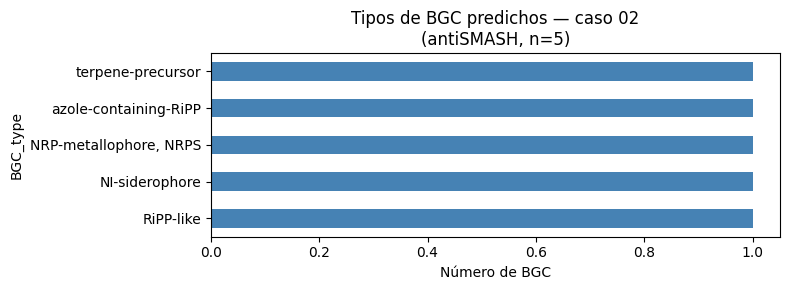

✅ Gráfico guardado en genome_annotation/caso_02/results/antismash_results/bgc_tipos_02.pdf


In [35]:
# Distribución de tipos de BGC
if "bgc_df" not in globals() or bgc_df.empty:
    print("ℹ️ No hay BGC que graficar en este caso (antiSMASH no predijo ninguno)")
else:
    tipo_counts = bgc_df["BGC_type"].value_counts()

    fig, ax = plt.subplots(figsize=(8, max(3, 0.4 * len(tipo_counts) + 1)))
    tipo_counts.plot(kind="barh", ax=ax, color="steelblue")
    ax.set_xlabel("Número de BGC")
    ax.set_title(f"Tipos de BGC predichos — caso {CASO}\n(antiSMASH, n={len(bgc_df)})")
    ax.invert_yaxis()
    plt.tight_layout()

    bgc_plot = f"{antismash_out}/bgc_tipos_{CASO}.pdf"
    plt.rcParams["pdf.fonttype"] = 42
    plt.savefig(bgc_plot, bbox_inches="tight")
    plt.show()

    if not os.path.exists(bgc_plot) or os.path.getsize(bgc_plot) == 0:
        raise RuntimeError(f"❌ No se guardó el gráfico en {bgc_plot}")
    print(f"✅ Gráfico guardado en {bgc_plot}")

**Preguntas — antiSMASH:**

26. ¿Cuántos BGC predijo antiSMASH en el genoma de su caso?
27. ¿Qué tipos de BGC están presentes? ¿Cuál es el más frecuente?
28. ¿Alguno de los BGC tiene homología con un clúster conocido según KnownClusterBlast (ej. un antibiótico, sideróforo o metabolito reportado en la literatura para su especie)?
29. ¿Hay BGC sin homología conocida en MIBiG? ¿Cuántos? ¿Qué implicaría caracterizar uno de ellos experimentalmente?
30. Elija un BGC que le llame la atención y describa: tipo, tamaño en pb y metabolito predicho.
31. Si su caso **no** tenía antiSMASH recomendado pero igual lo ejecutó: ¿encontró BGC? ¿Cómo se compara en número/diversidad con un caso que sí esté marcado como recomendado (puede comparar con un compañero)?

## 📦 Paso 10 — Comprimir todos los resultados

In [36]:
all_results_archive = f"{workdir}/results/all_results.zip"

# Comprimir toda la carpeta de resultados
!zip -r "{all_results_archive}" "{workdir}/results"

print(f"\n✅ Todos los resultados comprimidos en: {all_results_archive}")
print("Puedes descargar este archivo desde el explorador de archivos de Colab.")

  adding: genome_annotation/caso_02/results/ (stored 0%)
  adding: genome_annotation/caso_02/results/integron_results/ (stored 0%)
  adding: genome_annotation/caso_02/results/integron_results/Results_Integron_Finder_contigs/ (stored 0%)
  adding: genome_annotation/caso_02/results/integron_results/Results_Integron_Finder_contigs/contigs.summary (deflated 53%)
  adding: genome_annotation/caso_02/results/integron_results/Results_Integron_Finder_contigs/integron_finder.out (deflated 85%)
  adding: genome_annotation/caso_02/results/integron_results/Results_Integron_Finder_contigs/contigs.integrons (deflated 61%)
  adding: genome_annotation/caso_02/results/amrfinder_results/ (stored 0%)
  adding: genome_annotation/caso_02/results/amrfinder_results/amrfinder.tsv (deflated 71%)
  adding: genome_annotation/caso_02/results/antismash_results/ (stored 0%)
  adding: genome_annotation/caso_02/results/antismash_results/contigs.gbk (deflated 66%)
  adding: genome_annotation/caso_02/results/antismash_r

## ❓ Preguntas integradoras

**Todos los casos:**

32. Considerando los resultados de Bakta, AMRFinderPlus y PlasmidFinder: ¿qué puede concluir sobre la movilidad de los genes de resistencia en su caso?
33. Si un gen de resistencia está en un plásmido que también contiene un integrón, ¿qué implica para la diseminación de resistencias?
34. ¿Todos los contigs con plásmidos pertenecen claramente al organismo de estudio? ¿Cómo lo verificaría?
35. Si su caso tiene grupo taxonómico en AMRFinderPlus (ver tabla de casos): ¿los resultados son consistentes con lo que esperaría para esa especie/cepa según la guía del Módulo 5?

**Si ejecutó antiSMASH (Paso 9):**

36. ¿Cuántos BGC identificó Bakta en su anotación estándar (sección de la salida relacionada con regiones/clusters)? ¿Coincide con los predichos por antiSMASH? ¿Por qué podrían diferir?
37. Compare el número de BGC predichos con lo reportado en la literatura para su especie (si existe). ¿Cuántos tienen producto conocido y cuántos son "silenciosos" o sin homología en MIBiG?
38. ¿Qué ventaja tiene usar un genoma *finished* (como el GCF_*/GCA_*.1 de referencia usado aquí) en lugar de un borrador (*draft*) con muchos contigs para este tipo de análisis?

---
*Consulte la [guía compartida](00_genome_annotation_common.md) y el [README del Módulo 6](../README.md) para repasar los conceptos.*